# Human versus AI label consistency

The first 200 rows are human-labelled and the remaining rows are AI-labelled.


In [1]:
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, cohen_kappa_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

csv_path = r"../src/labeled_data/labeled_data.csv"
df = pd.read_csv(csv_path)
bert_features = [c for c in df.columns if c.lower().startswith("bert_")]
non_bert_features = [c for c in df.select_dtypes(include="number").columns if c not in bert_features]
X = df[non_bert_features]
y = (df["label"] == "Deserving of reward").astype(int)
X_human, X_ai = X.iloc[:200], X.iloc[200:]
y_human, y_ai = y.iloc[:200], y.iloc[200:]
models = {
    "Logistic regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=3000, C=0.1)),
    "Random forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=500, min_samples_leaf=3, max_features="sqrt", random_state=42, n_jobs=-1)),
    "ExtraTrees": make_pipeline(SimpleImputer(strategy="median"), ExtraTreesClassifier(n_estimators=500, min_samples_leaf=3, max_features="sqrt", random_state=42, n_jobs=-1)),
}
for name, model in models.items():
    model.fit(X_human, y_human)
    prediction = model.predict(X_ai)
    print(name, accuracy_score(y_ai, prediction), balanced_accuracy_score(y_ai, prediction), cohen_kappa_score(y_ai, prediction))


## Top 15 content-quality features plus combined BERT importance

Importances are shown as percentages of total importance. All `bert_dim_*` importances are summed into one `BERT (combined)` category.


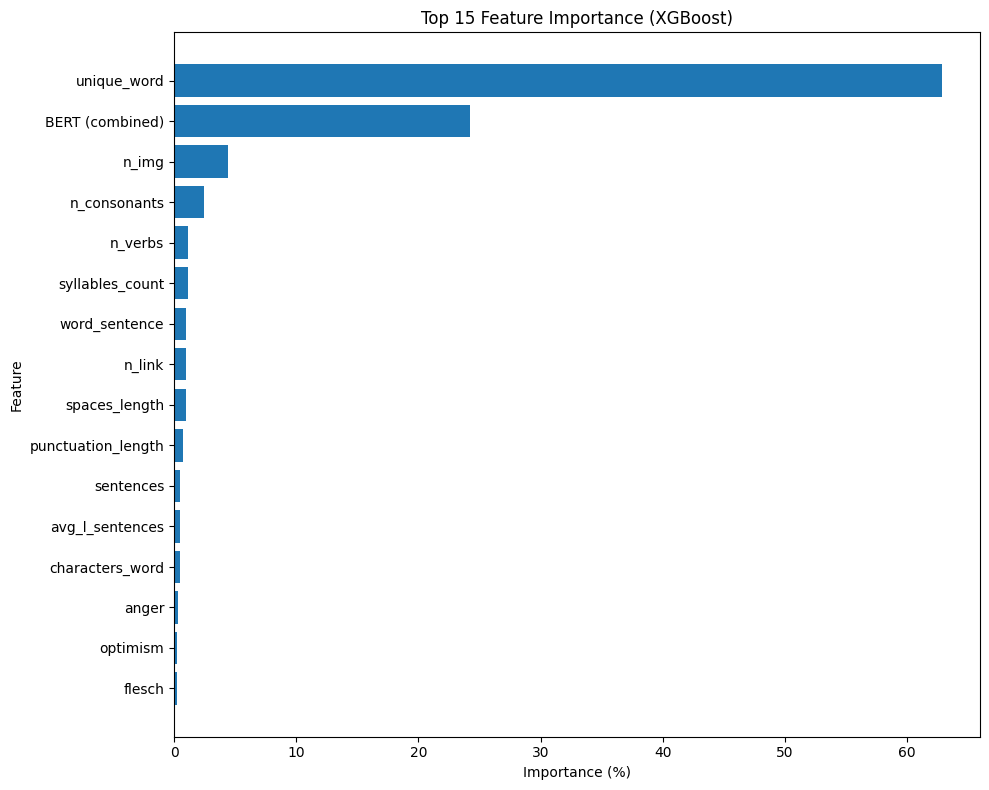

,Feature,Importance,Importance (%)
0,unique_word,0.166973,62.819280
15,BERT (combined),0.064325,24.200463
1,n_img,0.011779,4.431439
2,n_consonants,0.006472,2.435062
3,n_verbs,0.003108,1.169239
4,syllables_count,0.002964,1.115123
5,n_link,0.002592,0.975037
6,word_sentence,0.002592,0.975037
7,spaces_length,0.002586,0.973042
8,punctuation_length,0.001982,0.745687


In [5]:
import matplotlib.pyplot as plt

importance_path = r"../content_quality_feature_importance.csv"
importance_df = pd.read_csv(importance_path)
is_bert = importance_df["Feature"].str.lower().str.startswith("bert_")
total_importance = importance_df["Importance"].sum()
top_non_bert = importance_df[~is_bert].nlargest(15, "Importance")
bert_total = importance_df.loc[is_bert, "Importance"].sum()
plot_df = pd.concat([top_non_bert[["Feature", "Importance"]], pd.DataFrame({"Feature": ["BERT (combined)"], "Importance": [bert_total]})], ignore_index=True)
plot_df["Importance (%)"] = plot_df["Importance"] / total_importance * 100
plot_df = plot_df.sort_values("Importance (%)")
plt.figure(figsize=(10, 8))
bars = plt.barh(plot_df["Feature"], plot_df["Importance (%)"])
plt.xlabel("Importance (%)")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importance (XGBoost)")
for bar, value in zip(bars, plot_df["Importance (%)"]):
    plt.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, "", va="center")
plt.tight_layout()
plt.savefig("../top15_content_quality_features_with_bert_combined.png", dpi=300, bbox_inches="tight")
plt.show()
plot_df.sort_values("Importance (%)", ascending=False)
